# SpamJam: modelling

SpamJam flags spam (`is_spam` = 1) for GrandPied's IT team. The problem is described in the README, and the data is explored and split in `data_exploration.ipynb`. Here we build and compare models on the training set.

**What guides our choices.** For GrandPied, a false positive (a client email flagged as spam) costs more than a false negative (spam that gets through). So:
- **Metric:** we compare models with average precision, then pick a decision threshold on out-of-fold predictions that keeps precision on spam high.
- **Protocol:** every choice is made on the training set with cross-validation; the test set is used once, at the end.

**Scope.** This is a proof of concept on Spambase, whose legitimate emails all come from one person. GrandPied would retrain the model on its own emails before real use.

## Preprocessing pipeline

All steps run inside a scikit-learn `Pipeline`, so each CV fold learns them from its training part only.

- **Capital-letter counts:** log, then `StandardScaler`. They are very skewed (see `data_exploration.ipynb`).
- **Other features:** `StandardScaler` only.
- **No imputation** (no missing values) and **no encoding** (all features are numeric).

We scale because k-NN, the linear SVM and regularised logistic regression are sensitive to feature size.

**Decision rule:** an option wins only if its CV average precision beats the other by more than one standard error; otherwise we keep the simpler one.

## Log transform and L1 vs L2

In [1]:
import numpy as np
import pandas as pd
import yaml
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import FunctionTransformer

from spamjam.constants import CONFIG_PATH
from spamjam.data import DatasetLoader
from spamjam.features import build_pipeline

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

loader = DatasetLoader.from_config()
train_df, _ = loader.load_split()   # test set not used until the end

with open(CONFIG_PATH, encoding="utf-8") as f:
    config = yaml.safe_load(f)
donor = config["features"]["donor_columns"]

X_train = train_df.drop(columns="is_spam")
y_train = train_df["is_spam"]

grid = {
    "preprocess__capital__log": [
        FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
        "passthrough",                      # = no log transform
    ],
    "model__penalty": ["l1", "l2"],
    "model__C": [0.01, 0.1, 1, 10],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config["random_state"])
search = GridSearchCV(
    build_pipeline(LogisticRegression(solver="liblinear")),
    grid, cv=cv, scoring="average_precision", n_jobs=-1,
).fit(X_train, y_train)

In [2]:
results = pd.DataFrame(search.cv_results_)

results["log"] = results["param_preprocess__capital__log"].map(
    lambda v: "no" if isinstance(v, str) else "yes")
cols = ["log", "param_model__penalty", "param_model__C",
        "mean_test_score", "std_test_score"]
best = results.loc[results.groupby(["log", "param_model__penalty"])
                   ["mean_test_score"].idxmax(), cols]
best.sort_values("mean_test_score", ascending=False).round(4)

,log,param_model__penalty,param_model__C,mean_test_score,std_test_score
8,yes,l1,1.0,0.9541,0.0111
14,yes,l2,10.0,0.9530,0.0091
9,no,l1,1.0,0.9434,0.0112
15,no,l2,10.0,0.9425,0.0098


**Decisions.**
- **Log transform: keep it.** With the log, the best CV average precision is about 0.954; without it, about 0.944. The gain (~0.010) is about two standard errors, so it is a real improvement.
- **L1 vs L2: L1.** The best L1 (C=1) and L2 (C=10) scores differ by about 0.001, well within one standard error. Following our rule, we keep the simpler model: L1, which also sets weak features to zero.

## Coefficients: L1 vs L2

We refit the best L1 and best L2 pipelines on the training set and compare their 20 largest weights. A positive weight pushes an email towards spam, a negative one towards ham. Features are scaled, so sizes can be compared.

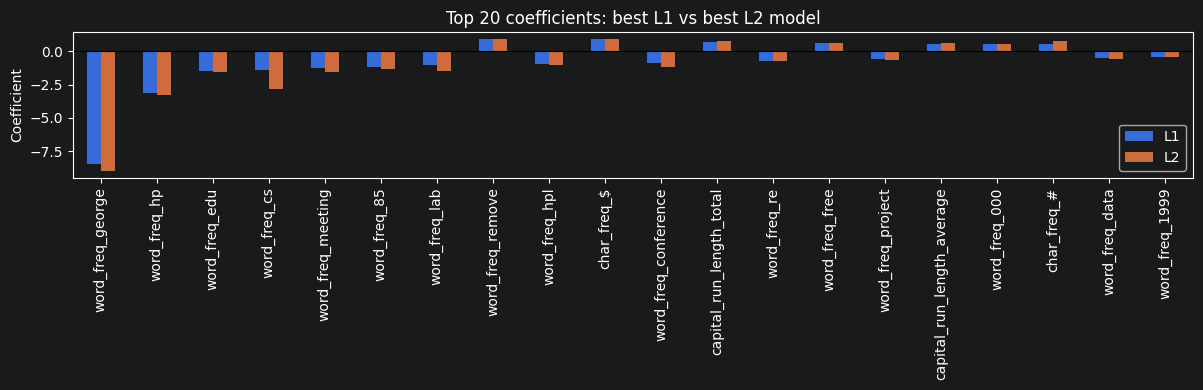

L1 sets 2 of 57 coefficients to zero.


In [3]:
import matplotlib.pyplot as plt
from sklearn.base import clone


def refit_best(penalty: str):
    """Refit the best pipeline for one penalty (with the log transform) on the training set."""
    rows = results[(results["log"] == "yes") & (results["param_model__penalty"] == penalty)]
    params = rows.loc[rows["mean_test_score"].idxmax(), "params"]
    return clone(search.estimator).set_params(**params).fit(X_train, y_train)


models = {"L1": refit_best("l1"), "L2": refit_best("l2")}
names = models["L1"]["preprocess"].get_feature_names_out()
coefs = pd.DataFrame(
    {label: m["model"].coef_[0] for label, m in models.items()},
    index=[n.split("__", 1)[1] for n in names],
)

top = coefs.loc[coefs["L1"].abs().sort_values(ascending=False).index[:20]]
top.plot.bar(figsize=(12, 4), title="Top 20 coefficients: best L1 vs best L2 model")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Coefficient")
plt.tight_layout()
plt.show()

print(f"L1 sets {(coefs['L1'] == 0).sum()} of {len(coefs)} coefficients to zero.")

Both models agree on the main signals. The largest weight by far is `word_freq_george` (strongly towards ham), followed by other donor-related words (`hp`, `edu`, `cs`, `meeting`, `lab`), while `remove`, `$` and capital letters push towards spam. L1 sets only `857` and `415` to zero, the two near-duplicate features (correlation 0.994). This dependence on the donor's words is what we test next.

## Donor-specific words

Some words describe the dataset's donor (George, at HP Labs) rather than spam: `george`, `hp`, `hpl`, `650`, `857`, `415`, `labs`, `telnet`, `technology` (see `data_exploration.ipynb`). We rerun the search without them.

CV can only partly judge this: its folds come from the same donor, so these words look useful here even though they wouldn't help on GrandPied's emails.

In [4]:
search_dropped = GridSearchCV(
    build_pipeline(LogisticRegression(solver="liblinear")),
    grid, cv=cv, scoring="average_precision", n_jobs=-1,
).fit(X_train.drop(columns=donor), y_train)

std_best = search.cv_results_["std_test_score"][search.best_index_]
one_se = std_best / np.sqrt(cv.get_n_splits())

print(f"All features:        {search.best_score_:.4f}")
print(f"Without donor words: {search_dropped.best_score_:.4f}")
print(f"Difference:          {search.best_score_ - search_dropped.best_score_:.4f}")
print(f"One standard error:  {one_se:.4f}")

All features:        0.9541
Without donor words: 0.9382
Difference:          0.0160
One standard error:  0.0050


**Decision: keep them.** Dropping them lowers CV average precision from about 0.954 to 0.938 (about three standard errors). That gain comes from the donor's own emails and wouldn't carry over to GrandPied. Since this is a proof of concept on Spambase, we keep them and report the limitation: our scores are likely optimistic for GrandPied, and the model must be retrained on GrandPied's own emails before real use.

## Feature Selection via GridSearchCV

**Why?**
To simplify the model and prevent overfitting, we need to remove useless features. Lasso (L1 regularization) is a great tool for this because it mathematically shrinks the coefficients of useless or redundant features to exactly `0.0`.

**How?**
Instead of arbitrarily picking a penalty threshold, we use `GridSearchCV` to test multiple values of the regularization parameter `C` (pulled dynamically from `config.yaml`). We find the best `C` using Cross-Validation, fit the model, and drop any feature whose coefficient is exactly `0`.

*Note: We wrap the scaler and model in a `Pipeline` to ensure no data leakage occurs during the Cross-Validation.*

## **Lasso Pipeline Definition + Scaling**

In [5]:
lasso_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty='l1', solver='liblinear', random_state=config['random_state'])
)

## **Grid parameters and CV folds**

In [6]:
param_grid = {'logisticregression__C': config['grid_search']['lasso_C']}
cv_folds = config['grid_search']['cv_folds']

In [7]:
print("Running GridSearchCV to tune Lasso penalty...")
grid_search = GridSearchCV(lasso_pipeline, param_grid, cv=cv_folds, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

Running GridSearchCV to tune Lasso penalty...


,estimator,Pipeline(step...liblinear'))])
,param_grid,"{'logisticregression__C': [0.01, 0.1, ...]}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


## **Extract the best model and its coefficients**

In [8]:
best_lasso = grid_search.best_estimator_
best_c = grid_search.best_params_['logisticregression__C']
print(f" Best C found: {best_c}")

coefs = best_lasso.named_steps['logisticregression'].coef_[0]

 Best C found: 1.0


## **Identification of the columns to drop**

In [9]:
useless_columns = X_train.columns[coefs == 0].tolist()
useful_columns = X_train.columns[coefs != 0].tolist()

print(f" Lasso dropped {len(useless_columns)} useless columns:")
print(useless_columns)

 Lasso dropped 3 useless columns:
['word_freq_857', 'word_freq_415', 'capital_run_length_average']


## **The reduced training set**

In [10]:
X_train_reduced = X_train[useful_columns]
print(f" Reduced training set shape: {X_train_reduced.shape}")

 Reduced training set shape: (3368, 54)


## Baseline Model Development

**Why?**
Before training complex models, we need a baseline. A `DummyClassifier` predicts the majority class without looking at the data (always predicting Ham/0). If our machine learning models cannot beat this baseline, it means our features are useless.

**How?**
We evaluate the `DummyClassifier` using the exact same Cross-Validation strategy (`StratifiedKFold`) on the reduced dataset.

*Note: We use `make_scorer` with `zero_division=0` to prevent red warnings. Because the Dummy model never predicts Spam, the denominator of the Precision formula is 0. Setting it to 0 cleanly handles this edge case.*

## **Define Cross-Validation strategy and Dummy Baseline**

In [11]:
cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=config['random_state'])

dummy_model = DummyClassifier(strategy="most_frequent")

## **Scoring metrics**

In [12]:
scoring = {
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc'
}


## **Evaluation**

In [13]:
print("Evaluating Dummy Baseline")
dummy_scores = cross_validate(dummy_model, X_train_reduced, y_train, cv=cv, scoring=scoring)

Evaluating Dummy Baseline


## **Results**

In [14]:
results_df = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Dummy Baseline': [
        dummy_scores['test_precision'].mean(),
        dummy_scores['test_recall'].mean(),
        dummy_scores['test_f1'].mean(),
        dummy_scores['test_roc_auc'].mean()
    ]
})

print(" Baseline Model Performance ")
display(results_df.round(4))

 Baseline Model Performance 


,Metric,Dummy Baseline
0,Precision,0.0
1,Recall,0.0
2,F1-Score,0.0
3,ROC-AUC,0.5


**Results Interpretation:**
As expected, the `DummyClassifier` yields a Precision, Recall, and F1-score of `0.0`. This is because it simply predicts "Ham" for every email, completely missing all the Spams (0 True Positives). Its ROC-AUC is `0.5`, which is the equivalent of random guessing.

This establishes the absolute "floor" for our project. Any real model we train next must score significantly higher than this table to prove it has learned something useful from the email features.